# Credit Risk Analysis: Exploratory Data Analysis

## Project overview
This project explores a consumer credit-risk dataset to understand its data quality and examine how applicant and loan characteristics relate to `loan_status`.

**Questions explored**
- What missing values, duplicate records, and implausible values need attention?
- How does the observed loan-status distribution vary across loan grade, home ownership, and loan intent?
- How do income, loan amount, interest rate, employment length, and loan-to-income proportion differ by loan status?

**Scope:** This is an exploratory data analysis (EDA) project. It does not train or evaluate a machine-learning model, and the associations shown here should not be interpreted as causal effects.

**Target interpretation:** In the commonly distributed version of this dataset, `loan_status = 1` represents default, while `loan_status = 0` represents non-default. This interpretation follows the dataset's commonly used target encoding.

**Data provenance:** The dataset is used for exploratory analysis of consumer credit risk. Its original source and applicable usage terms should be documented in the project README to support transparency and reproducibility.


## 1. Import libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent visual defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

## 2. Load the dataset

The dataset is loaded from a CSV file into a Pandas DataFrame for analysis. The notebook uses a relative file path to locate the dataset within the project directory, keeping the analysis organized and reproducible.

In [2]:
candidate_paths = [
    Path("../data/credit_risk_dataset.csv"),
    Path("data/credit_risk_dataset.csv"),
    Path("credit_risk_dataset.csv"),
]

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Could not find credit_risk_dataset.csv. "
        "Place it in ../data/, data/, or the notebook's current folder."
    )

df_raw = pd.read_csv(data_path)
df = df_raw.copy()

print(f"Loaded: {data_path}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Loaded: ..\data\credit_risk_dataset.csv
Rows: 32,581 | Columns: 12


## 3. First look at the data

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.tail()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26
32580,66,42000,RENT,2.0,MEDICAL,B,6475,9.99,0,0.15,N,30


In [5]:
df.shape

(32581, 12)

In [6]:
df.columns.tolist()

['person_age',
 'person_income',
 'person_home_ownership',
 'person_emp_length',
 'loan_intent',
 'loan_grade',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_default_on_file',
 'cb_person_cred_hist_length']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [9]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
person_age,32581.0,NaN,NaN,NaN,27.7346,6.348078,20.0,23.0,26.0,30.0,144.0
person_income,32581.0,NaN,NaN,NaN,66074.84847,61983.119168,4000.0,38500.0,55000.0,79200.0,6000000.0
person_home_ownership,32581,4,RENT,16446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
person_emp_length,31686.0,NaN,NaN,NaN,4.789686,4.14263,0.0,2.0,4.0,7.0,123.0
loan_intent,32581,6,EDUCATION,6453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_grade,32581,7,A,10777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,32581.0,NaN,NaN,NaN,9589.371106,6322.086646,500.0,5000.0,8000.0,12200.0,35000.0
loan_int_rate,29465.0,NaN,NaN,NaN,11.011695,3.240459,5.42,7.9,10.99,13.47,23.22
loan_status,32581.0,NaN,NaN,NaN,0.218164,0.413006,0.0,0.0,0.0,0.0,1.0
loan_percent_income,32581.0,NaN,NaN,NaN,0.170203,0.106782,0.0,0.09,0.15,0.23,0.83


In [10]:
print("Column data types:")
display(df.dtypes.to_frame("dtype"))

print("\nUnique values in the target column:")
display(df["loan_status"].value_counts(dropna=False).sort_index())

Column data types:


,dtype
person_age,int64
person_income,int64
person_home_ownership,object
person_emp_length,float64
loan_intent,object
loan_grade,object
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64



Unique values in the target column:


loan_status
0    25473
1     7108
Name: count, dtype: int64

## 4. Data quality checks

Check missing values, exact duplicate rows, and unusual values before cleaning. These checks help distinguish genuine observations from records that may need investigation; an extreme value is not automatically an error.

In [11]:
missing_summary = (
    df.isna()
      .sum()
      .rename("missing_count")
      .to_frame()
)
missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(df) * 100
).round(2)

missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
loan_int_rate,3116,9.56
person_emp_length,895,2.75
person_income,0,0.00
person_age,0,0.00
person_home_ownership,0,0.00
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_status,0,0.00
loan_percent_income,0,0.00


In [12]:
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count:,}")

Exact duplicate rows: 165


In [13]:
# Inspect examples before deciding how to handle exact duplicates.
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


In [14]:
# Check potentially implausible or extreme values.
quality_checks = {
    "person_age_over_100": int((df["person_age"] > 100).sum()),
    "person_age_under_18": int((df["person_age"] < 18).sum()),
    "employment_length_over_60": int((df["person_emp_length"] > 60).sum()),
    "employment_length_greater_than_age": int(
        (df["person_emp_length"] > df["person_age"]).sum()
    ),
    "income_over_1m": int((df["person_income"] > 1_000_000).sum()),
}
pd.Series(quality_checks, name="row_count").to_frame()

,row_count
person_age_over_100,5
person_age_under_18,0
employment_length_over_60,2
employment_length_greater_than_age,2
income_over_1m,9


In [15]:
# Inspect extreme records instead of changing them without checking.
df.loc[
    (df["person_age"] > 100)
    | (df["person_emp_length"] > 60)
    | (df["person_emp_length"] > df["person_age"]),
    ["person_age", "person_income", "person_emp_length",
     "loan_amnt", "loan_int_rate", "loan_status"]
].head(20)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status
0,22,59000,123.0,35000,16.02,1
81,144,250000,4.0,4800,13.57,0
183,144,200000,4.0,6000,11.86,0
210,21,192000,123.0,20000,6.54,0
575,123,80004,2.0,20400,10.25,0
747,123,78000,7.0,20000,NaN,0
32297,144,6000000,12.0,5000,12.73,0


## 5. Prepare an analysis copy

The original dataset is preserved in `df_raw`, while data cleaning is performed on a separate copy named `df`.

Exact duplicate rows are removed to avoid counting identical records multiple times. Records with ages above 100 are excluded as implausible for this analysis. Negative employment lengths and employment lengths greater than the applicant's age are treated as missing values.

Missing employment lengths and interest rates are imputed using their respective medians. This approach is relatively robust to skewed distributions and extreme values, although imputation can affect the original data distribution.

These cleaning decisions are assumptions made for this exploratory analysis and may influence the resulting statistics and visualizations.

In [16]:
rows_before_cleaning = len(df)

# Remove exact duplicate records.
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Remove implausible ages (document this rule in the project README).
age_rows_removed = int((df["person_age"] > 100).sum())
df = df.loc[df["person_age"] <= 100].copy()

# Mark invalid employment lengths as missing before imputation.
negative_emp_rows = int((df["person_emp_length"] < 0).sum())
df.loc[df["person_emp_length"] < 0, "person_emp_length"] = np.nan

emp_greater_than_age = df["person_emp_length"] > df["person_age"]
emp_greater_than_age_rows = int(emp_greater_than_age.sum())
df.loc[emp_greater_than_age, "person_emp_length"] = np.nan

# Impute missing values using medians.
emp_median = df["person_emp_length"].median()
rate_median = df["loan_int_rate"].median()

df["person_emp_length"] = df["person_emp_length"].fillna(emp_median)
df["loan_int_rate"] = df["loan_int_rate"].fillna(rate_median)

cleaning_summary = pd.DataFrame({
    "step": [
        "Rows before cleaning",
        "Exact duplicate rows removed",
        "Rows removed for age > 100",
        "Negative employment lengths set to missing",
        "Employment lengths greater than age set to missing",
        "Rows after cleaning",
    ],
    "count": [
        rows_before_cleaning,
        duplicates_removed,
        age_rows_removed,
        negative_emp_rows,
        emp_greater_than_age_rows,
        len(df),
    ],
})
cleaning_summary

,step,count
0,Rows before cleaning,32581
1,Exact duplicate rows removed,165
2,Rows removed for age > 100,5
3,Negative employment lengths set to missing,0
4,Employment lengths greater than age set to mis...,2
5,Rows after cleaning,32411


In [17]:
print("Missing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))

print(f"\nFinal analysis shape: {df.shape}")

Missing values after cleaning:


,missing_count
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0



Final analysis shape: (32411, 12)


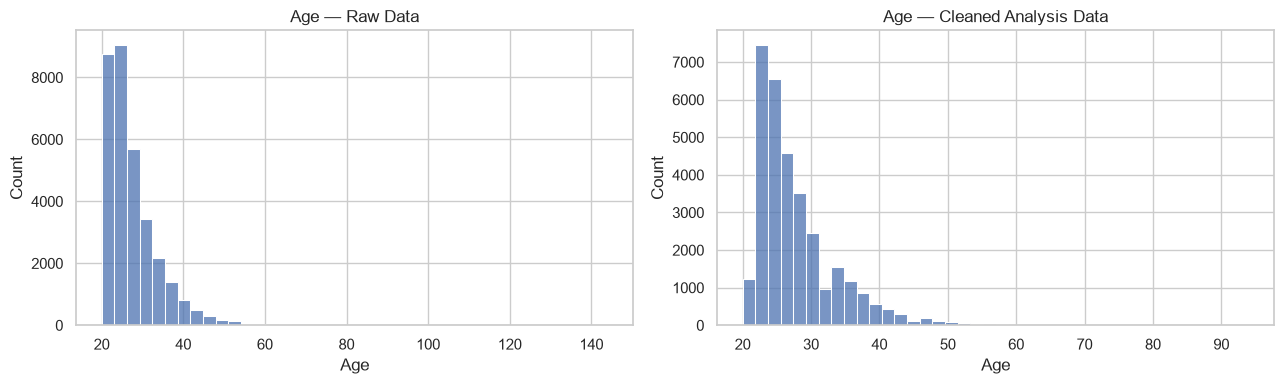

In [18]:
# Compare the raw and cleaned distributions for selected columns.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_raw["person_age"].dropna(), bins=40, ax=axes[0])
axes[0].set_title("Age — Raw Data")
axes[0].set_xlabel("Age")

sns.histplot(df["person_age"].dropna(), bins=40, ax=axes[1])
axes[1].set_title("Age — Cleaned Analysis Data")
axes[1].set_xlabel("Age")

plt.tight_layout()
plt.show()

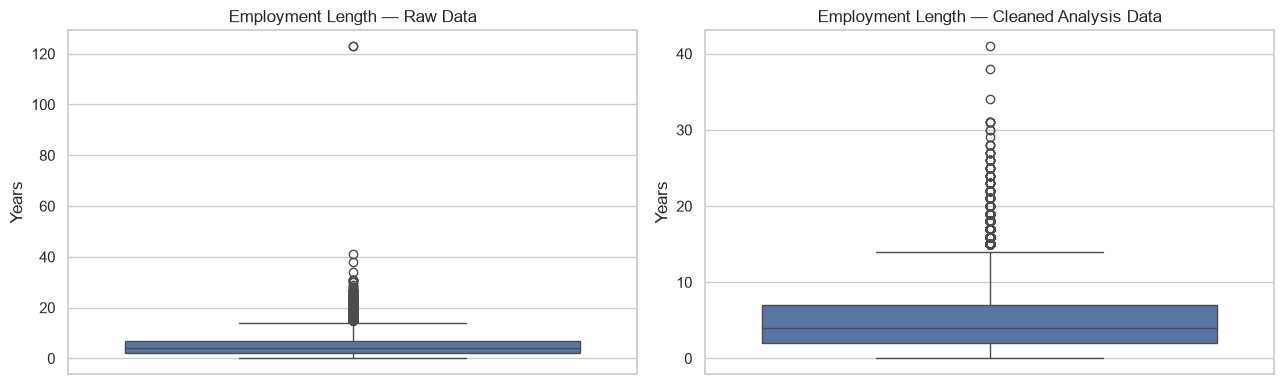

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(y=df_raw["person_emp_length"], ax=axes[0])
axes[0].set_title("Employment Length — Raw Data")
axes[0].set_ylabel("Years")

sns.boxplot(y=df["person_emp_length"], ax=axes[1])
axes[1].set_title("Employment Length — Cleaned Analysis Data")
axes[1].set_ylabel("Years")

plt.tight_layout()
plt.show()

## 6. Univariate analysis

These charts describe the distributions of individual features. Numeric variables are shown with histograms, while the target and categorical features are summarized with counts.

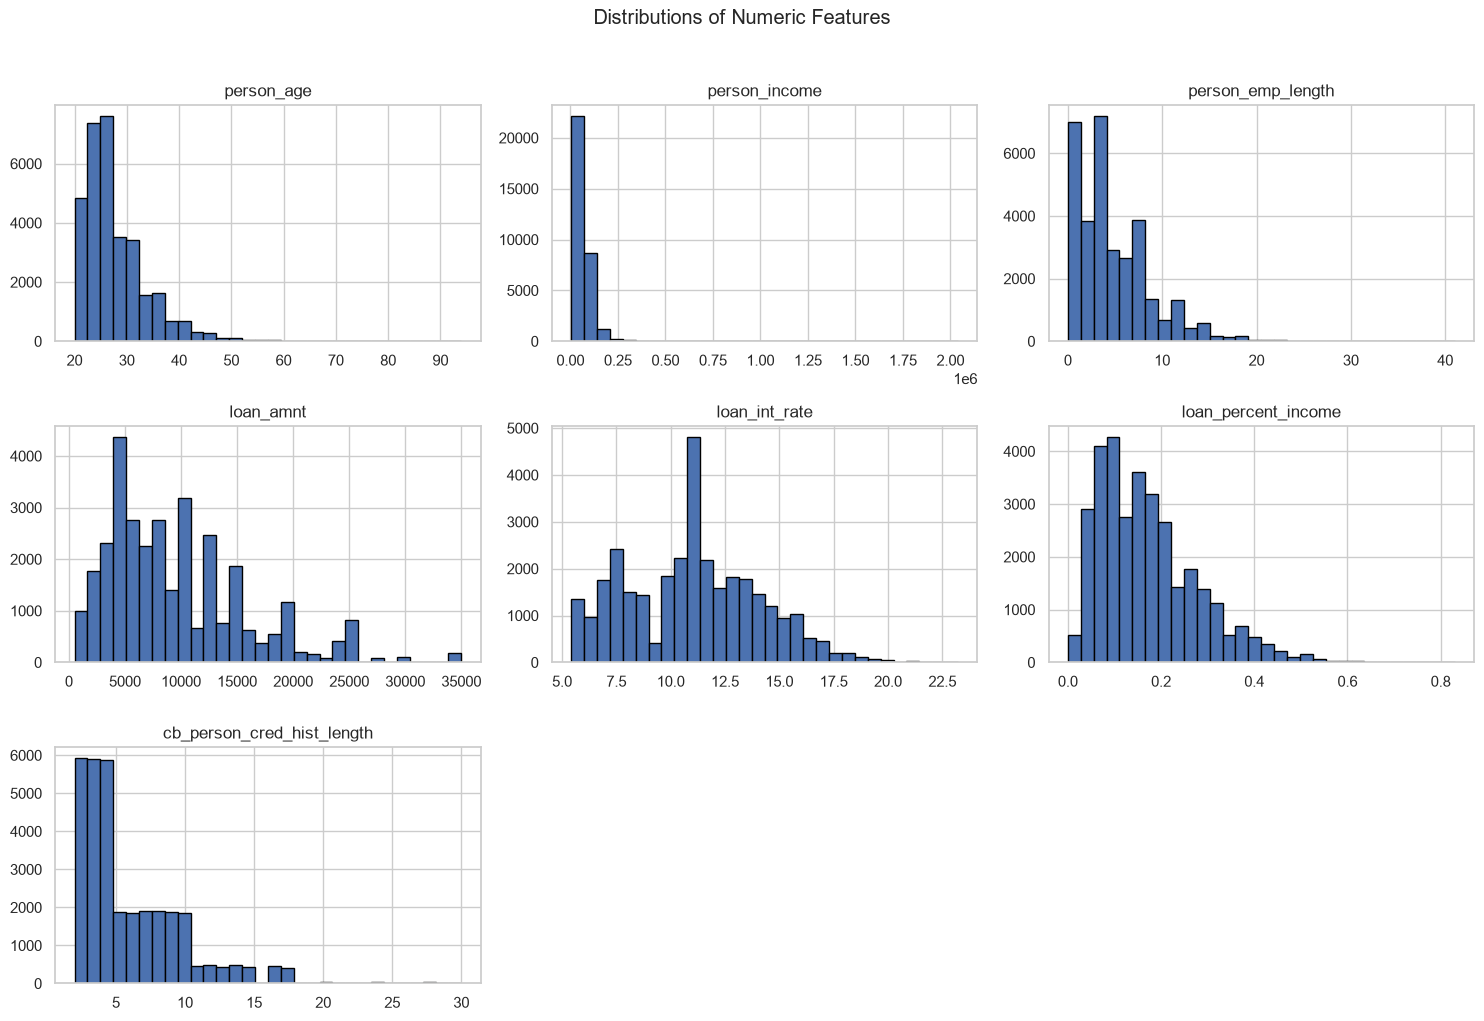

In [20]:
numeric_columns = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

df[numeric_columns].hist(bins=30, figsize=(15, 10), edgecolor="black")
plt.suptitle("Distributions of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

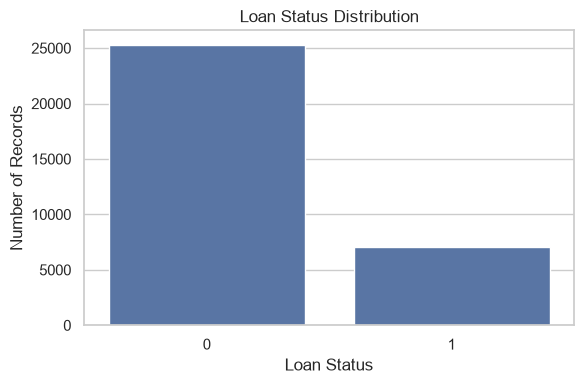

,count
loan_status,
0,25322
1,7089


In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="loan_status")
plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

df["loan_status"].value_counts().sort_index().to_frame("count")

In [22]:
categorical_columns = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]

for column in categorical_columns:
    print(f"\n{column} — value counts")
    display(df[column].value_counts(dropna=False).to_frame("count"))


person_home_ownership — value counts


,count
person_home_ownership,
RENT,16375
MORTGAGE,13367
OWN,2563
OTHER,106



loan_intent — value counts


,count
loan_intent,
EDUCATION,6409
MEDICAL,6042
VENTURE,5680
PERSONAL,5497
DEBTCONSOLIDATION,5189
HOMEIMPROVEMENT,3594



loan_grade — value counts


,count
loan_grade,
A,10703
B,10384
C,6436
D,3620
E,963
F,241
G,64



cb_person_default_on_file — value counts


,count
cb_person_default_on_file,
N,26681
Y,5730


## 7. Loan status versus categorical features

These comparisons show the observed status counts and within-category proportions. Proportions are more useful than raw counts when category sizes differ. Small categories should be interpreted cautiously.

In [23]:
grade_status_counts = pd.crosstab(df["loan_grade"], df["loan_status"])
display(grade_status_counts)

grade_status_rates = pd.crosstab(
    df["loan_grade"], df["loan_status"], normalize="index"
).round(3)
display(grade_status_rates)

loan_status,0,1
loan_grade,,
A,9637,1066
B,8689,1695
C,5100,1336
D,1482,2138
E,342,621
F,71,170
G,1,63


loan_status,0,1
loan_grade,,
A,0.900,0.100
B,0.837,0.163
C,0.792,0.208
D,0.409,0.591
E,0.355,0.645
F,0.295,0.705
G,0.016,0.984


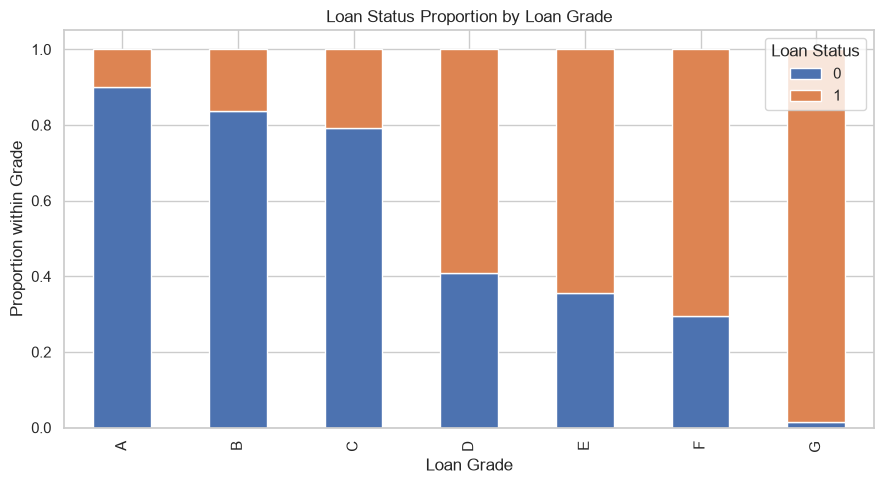

In [24]:
grade_status_rates.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Loan Status Proportion by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Proportion within Grade")
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

In [25]:
home_status_counts = pd.crosstab(
    df["person_home_ownership"], df["loan_status"]
)
display(home_status_counts)

home_status_rates = pd.crosstab(
    df["person_home_ownership"], df["loan_status"], normalize="index"
).round(3)
display(home_status_rates)

loan_status,0,1
person_home_ownership,,
MORTGAGE,11680,1687
OTHER,73,33
OWN,2371,192
RENT,11198,5177


loan_status,0,1
person_home_ownership,,
MORTGAGE,0.874,0.126
OTHER,0.689,0.311
OWN,0.925,0.075
RENT,0.684,0.316


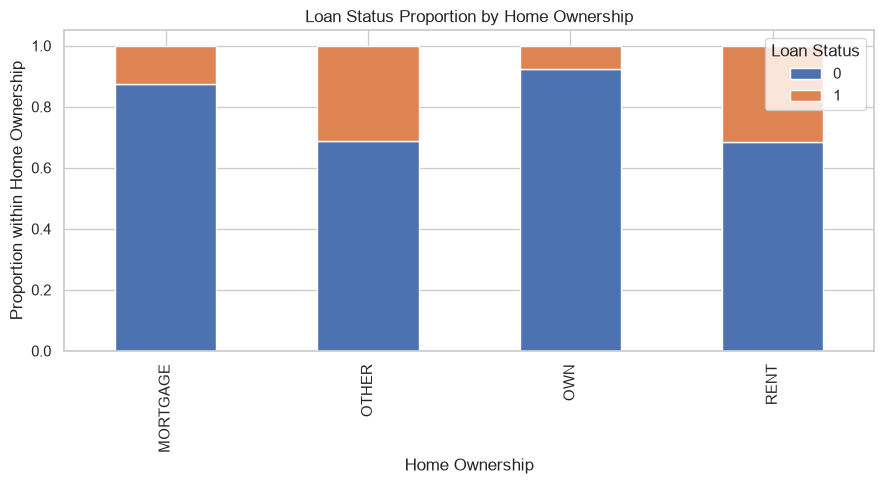

In [26]:
home_status_rates.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Loan Status Proportion by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Proportion within Home Ownership")
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

loan_status,0,1
loan_intent,,
DEBTCONSOLIDATION,0.713,0.287
EDUCATION,0.827,0.173
HOMEIMPROVEMENT,0.738,0.262
MEDICAL,0.732,0.268
PERSONAL,0.801,0.199
VENTURE,0.851,0.149


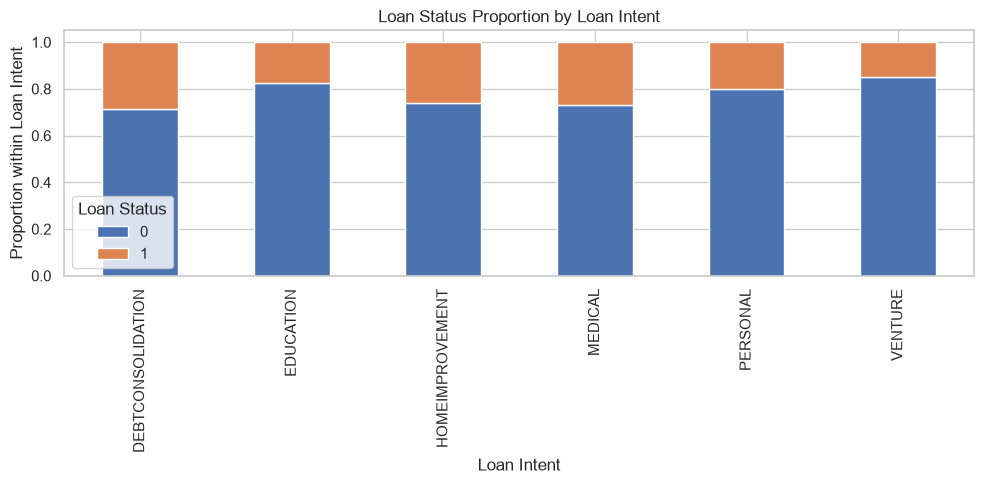

In [27]:
intent_status_rates = pd.crosstab(
    df["loan_intent"], df["loan_status"], normalize="index"
).round(3)

display(intent_status_rates)
intent_status_rates.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Loan Status Proportion by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Proportion within Loan Intent")
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

## 8. Loan status versus numeric features

Compare distributions and group summaries. These are descriptive comparisons; they do not establish that a feature causes default.

In [28]:
group_summary = (
    df.groupby("loan_status")[
        ["person_income", "loan_amnt", "loan_int_rate",
         "person_emp_length", "loan_percent_income"]
    ]
    .agg(["count", "mean", "median"])
    .round(2)
)
group_summary

person_income                    loan_amnt                    \
                    count      mean   median     count      mean  median   
loan_status                                                                
0                   25322  70602.15  60000.0     25322   9239.76  8000.0   
1                    7089  49094.50  41682.0      7089  10857.48  9600.0   

            loan_int_rate               person_emp_length               \
                    count   mean median             count  mean median   
loan_status                                                              
0                   25322  10.49  10.99             25322  4.94    4.0   
1                    7089  12.88  12.99              7089  4.11    3.0   

            loan_percent_income               
                          count  mean median  
loan_status                                   
0                         25322  0.15   0.13  
1                          7089  0.25   0.24

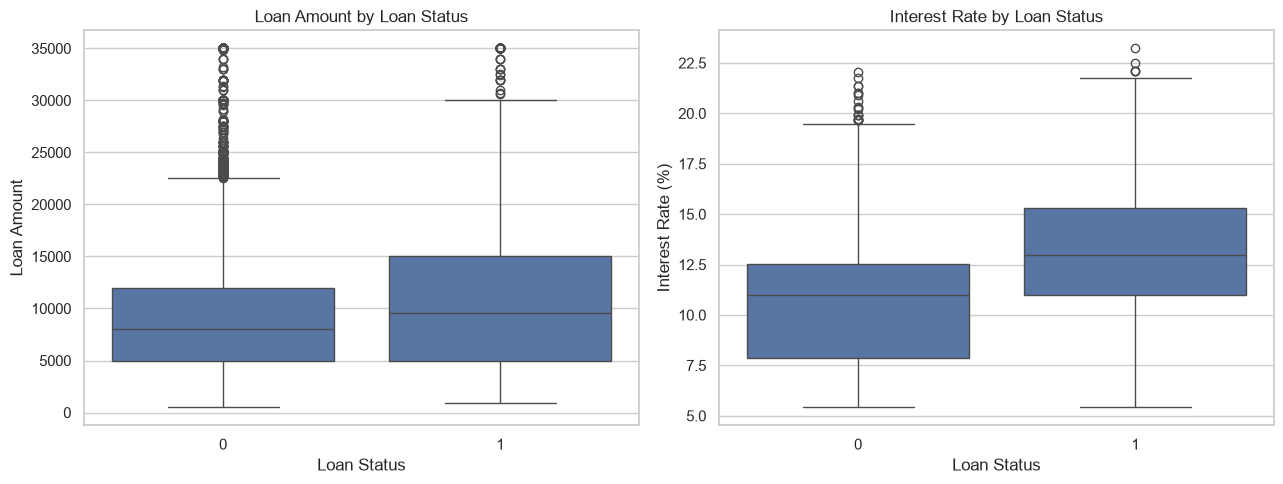

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="loan_status", y="loan_amnt", ax=axes[0])
axes[0].set_title("Loan Amount by Loan Status")
axes[0].set_xlabel("Loan Status")
axes[0].set_ylabel("Loan Amount")

sns.boxplot(data=df, x="loan_status", y="loan_int_rate", ax=axes[1])
axes[1].set_title("Interest Rate by Loan Status")
axes[1].set_xlabel("Loan Status")
axes[1].set_ylabel("Interest Rate (%)")

plt.tight_layout()
plt.show()

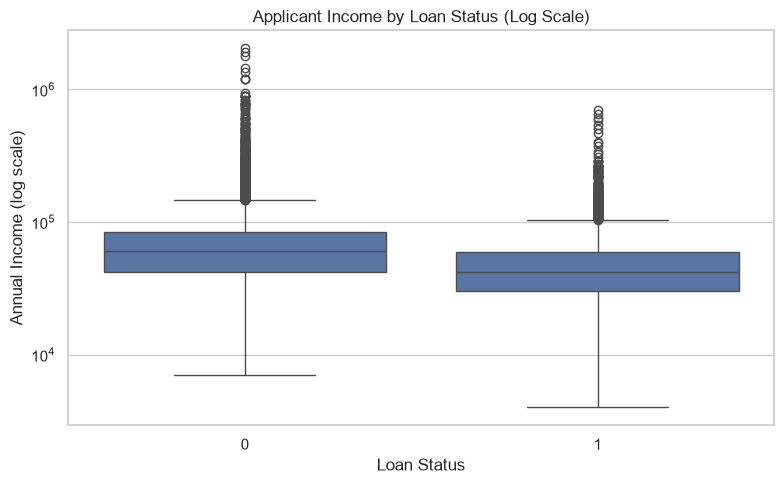

In [30]:
# Income is often highly skewed, so use a log scale for visualization.
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="loan_status", y="person_income")
plt.yscale("log")
plt.title("Applicant Income by Loan Status (Log Scale)")
plt.xlabel("Loan Status")
plt.ylabel("Annual Income (log scale)")
plt.tight_layout()
plt.show()

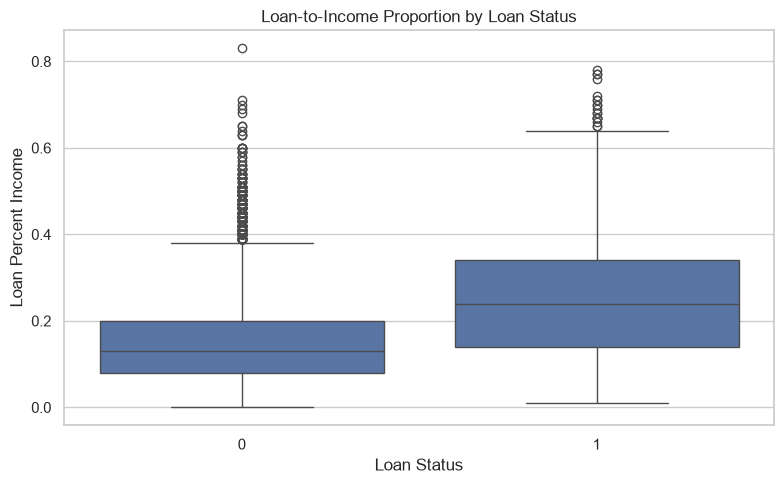

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="loan_status", y="loan_percent_income")
plt.title("Loan-to-Income Proportion by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Loan Percent Income")
plt.tight_layout()
plt.show()

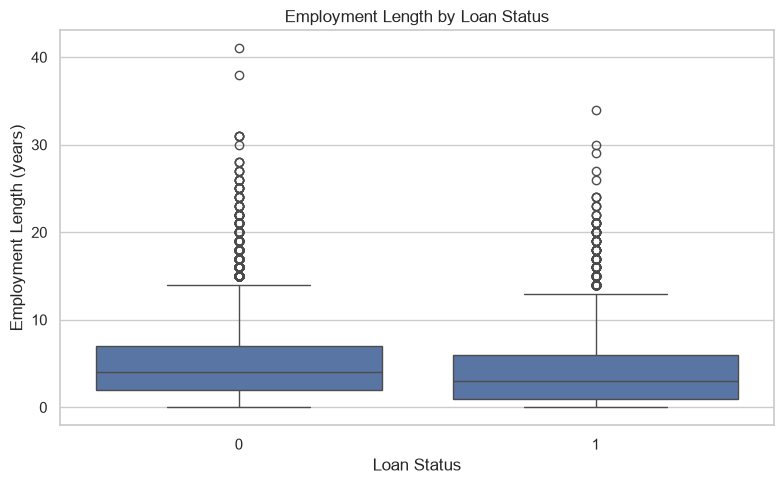

In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="loan_status", y="person_emp_length")
plt.title("Employment Length by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Employment Length (years)")
plt.tight_layout()
plt.show()

## 9. Correlation analysis

Correlation measures linear association, not causation. Binary-coded variables such as `loan_status` can be included, but their correlations need careful interpretation.

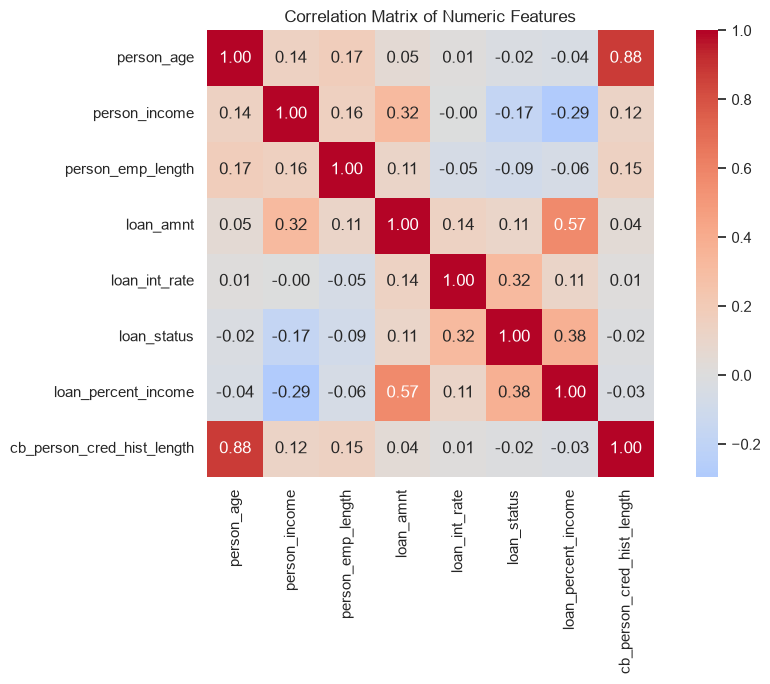

In [33]:
corr_columns = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_status",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

correlation_matrix = df[corr_columns].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

## 10. Key findings and interpretation

The following observations are based on the cleaned analysis dataset. In this dataset, `loan_status = 1` represents default and `loan_status = 0` represents non-default. The findings describe observed relationships within the dataset and should not be interpreted as causal effects.

- **Data quality:** The dataset began with 32,581 rows and 12 columns. The checks found 165 exact duplicate rows and 5 records with age above 100. The cleaning workflow removed those duplicate and age records, marked 2 implausible employment-length values as missing, and imputed missing employment length and interest rate with their medians. The resulting analysis dataset contains 32,411 rows and has no missing values in the checked columns.
- **Target balance:** `loan_status = 1` accounts for 7,089 records (21.87%); `loan_status = 0` accounts for 25,322 records (78.13%). The classes are imbalanced, so accuracy alone would be a poor metric if a prediction model were built later.
- **Loan grade:** The observed proportion with `loan_status = 1` rises from 10.0% for grade A and 16.3% for B to 59.1% for D, 70.5% for F, and 98.4% for G. Grade G has only 64 records, so its percentage should be interpreted cautiously. These are descriptive patterns, not proof that grade itself causes default.
- **Home ownership:** The observed `loan_status = 1` proportion is 31.6% for RENT, 12.6% for MORTGAGE, and 7.5% for OWN. The OTHER category has 31.1%, but only 106 records, making that estimate less stable.
- **Loan intent:** The observed `loan_status = 1` proportion is highest for DEBTCONSOLIDATION (28.7%) among the listed intents and lowest for VENTURE (14.9%). These proportions describe this dataset and should not be generalized automatically to other populations.
- **Numeric features:** Compared with `loan_status = 0`, the `loan_status = 1` group has a higher median loan amount (9,600 versus 8,000), higher median interest rate (12.99% versus 10.99%), and higher median loan-to-income proportion (0.24 versus 0.13). Its median annual income is lower (41,682 versus 60,000), and median employment length is lower (3 versus 4 years).
- **Interpretation limits:** These differences may reflect relationships among multiple features and the way the data was collected. EDA alone cannot establish causation, fairness, or model performance.

In [34]:
target_counts = df["loan_status"].value_counts().sort_index()
target_summary = pd.DataFrame({
    "count": target_counts,
    "proportion": (target_counts / target_counts.sum()).round(4),
})
target_summary

,count,proportion
loan_status,,
0,25322,0.7813
1,7089,0.2187


In [35]:
# A compact table of default/non-default proportions by loan grade.
# Confirm the target encoding against the dataset documentation before interpreting labels.
pd.crosstab(
    df["loan_grade"],
    df["loan_status"],
    normalize="index"
).round(3)

loan_status,0,1
loan_grade,,
A,0.900,0.100
B,0.837,0.163
C,0.792,0.208
D,0.409,0.591
E,0.355,0.645
F,0.295,0.705
G,0.016,0.984


## 11. Limitations and next steps

- The cleaning rules are analysis assumptions; verify them against the original dataset documentation.
- Median imputation is simple and reproducible, but it does not model why values are missing.
- Some categories are small, so their percentages can be unstable.
- The dataset's class distribution is imbalanced; any future model should be evaluated with metrics beyond accuracy, such as precision, recall, F1-score, and ROC-AUC or PR-AUC where appropriate.
- This notebook explores associations; it does not prove causality or assess whether lending decisions are fair.
- No model has been trained or evaluated here.
- Before publishing, cite the original dataset source and confirm the license/usage terms. A dataset being downloadable does not automatically mean it can be redistributed.
- A follow-up project could build a baseline classifier using a train/test split, compare appropriate metrics, guard against data leakage, and explain the model's limitations.

## 12. Reproducibility and publishing checklist

The notebook follows a consistent workflow for data loading, cleaning, and exploratory analysis. Its results depend on the availability of the dataset, the required Python libraries, and the execution of cells in the intended order.

The analysis documents its data-cleaning decisions and presents summary statistics and visualizations to support interpretation of the results. Reproducibility is supported by maintaining the notebook, dataset source information, and dependency requirements alongside the project documentation.

The repository should include a README describing the project objectives, dataset source and usage terms, cleaning methodology, key findings, and limitations. Dependencies should be listed in `requirements.txt`, while `.gitignore` should exclude notebook checkpoints and unnecessary local environment files. The dataset's redistribution terms should be checked before including the CSV in a public repository.